Using device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 21.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 398kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.23MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.2MB/s]


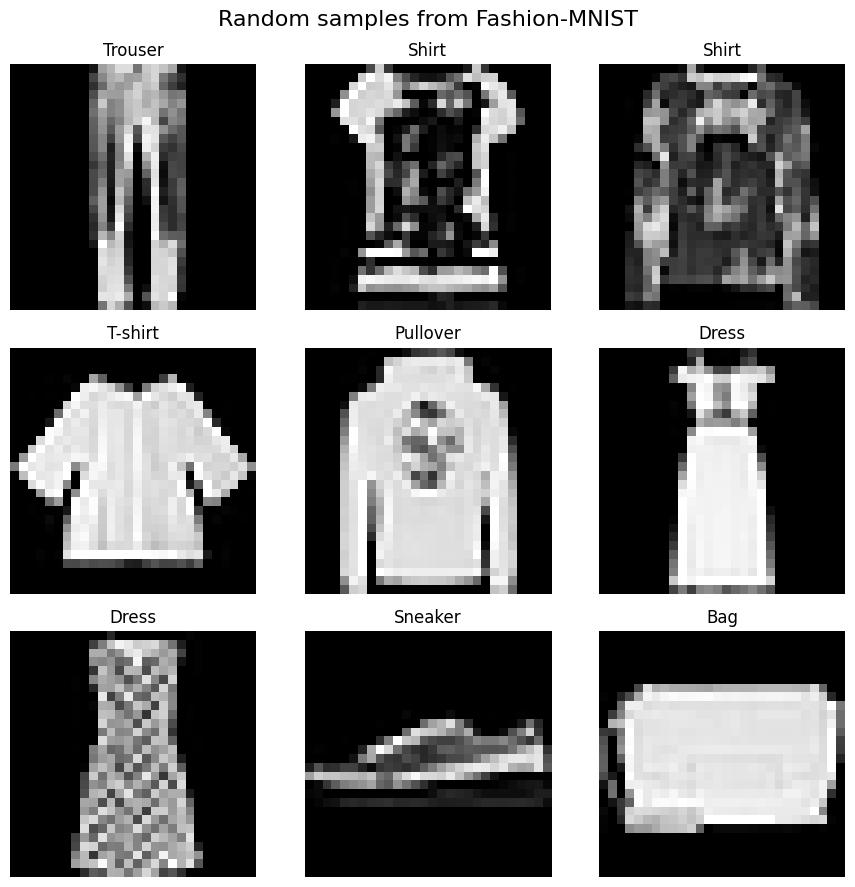

Total trainable parameters: 235,146
Epoch  1 | 15.2s | Train L: 0.9249 A: 0.7076 | Val L: 0.5894 A: 0.7893
Epoch  2 | 14.2s | Train L: 0.5149 A: 0.8167 | Val L: 0.4891 A: 0.8283
Epoch  3 | 14.0s | Train L: 0.4540 A: 0.8382 | Val L: 0.4536 A: 0.8388
Epoch  4 | 14.0s | Train L: 0.4220 A: 0.8498 | Val L: 0.4284 A: 0.8453
Epoch  5 | 14.0s | Train L: 0.3998 A: 0.8574 | Val L: 0.4138 A: 0.8530
Epoch  6 | 14.6s | Train L: 0.3819 A: 0.8636 | Val L: 0.3972 A: 0.8552
Epoch  7 | 15.0s | Train L: 0.3684 A: 0.8687 | Val L: 0.3887 A: 0.8617
Epoch  8 | 14.1s | Train L: 0.3548 A: 0.8735 | Val L: 0.3781 A: 0.8648
Epoch  9 | 14.3s | Train L: 0.3456 A: 0.8759 | Val L: 0.3673 A: 0.8703
Epoch 10 | 14.5s | Train L: 0.3348 A: 0.8795 | Val L: 0.3645 A: 0.8715
Epoch 11 | 14.5s | Train L: 0.3270 A: 0.8828 | Val L: 0.3607 A: 0.8715
Epoch 12 | 14.0s | Train L: 0.3189 A: 0.8864 | Val L: 0.3773 A: 0.8603
Epoch 13 | 14.1s | Train L: 0.3120 A: 0.8883 | Val L: 0.3465 A: 0.8767
Epoch 14 | 14.0s | Train L: 0.3054 A: 0.8

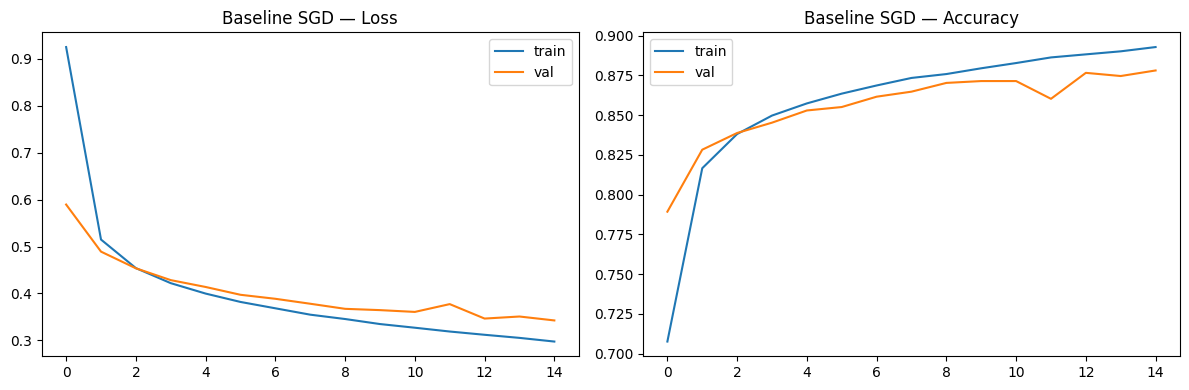

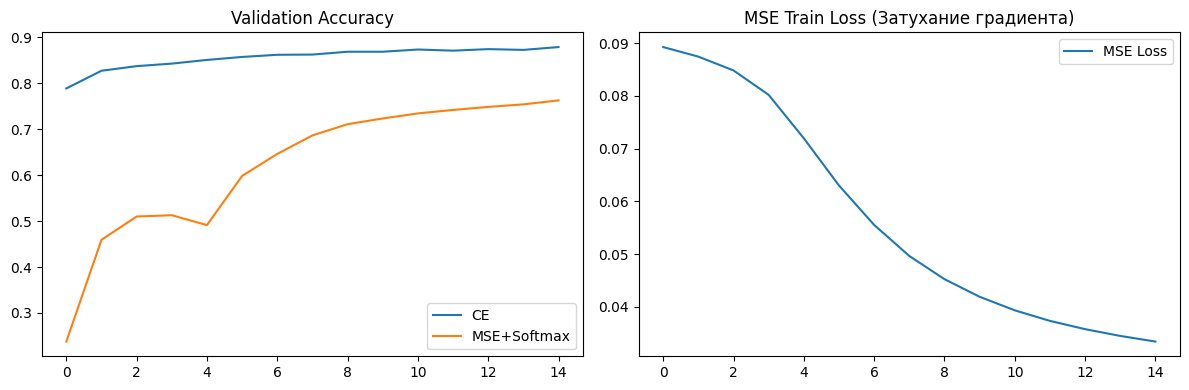

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import time
from copy import deepcopy

# Фиксация seed
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ================= ШАГ 1. Данные =================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

train_dataset = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Задание 1.1: Визуализация
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax in axes.flat:
    idx = np.random.randint(len(train_dataset))
    img, label = train_dataset[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.suptitle("Random samples from Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

# Задание 1.2: Split и DataLoader
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_subset, batch_size=256, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=2)

# ================= ШАГ 2. Архитектура =================
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_sizes=(256, 128), num_classes=10,
                 dropout_rate=0.0, use_batchnorm=False):
        super().__init__()
        layers = []
        prev_size = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_size, h))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            prev_size = h
        layers.append(nn.Linear(prev_size, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

model = MLP().to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")
# Ответ для отчета: 1 слой: 784*256+256 = 200,960. 2 слой: 256*128+128 = 32,896. Выход: 128*10+10 = 1,290.
# Всего ~235k. Для изображений нужно больше параметров, так как каждый пиксель (784) является отдельным признаком.

# ================= ШАГ 3. Цикл обучения =================
criterion = nn.CrossEntropyLoss()

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        running_loss += loss.item() * X_batch.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

def fit(model, train_loader, val_loader, criterion, optimizer, epochs=15, patience=5, verbose=True):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_weights, epochs_no_improve = float("inf"), deepcopy(model.state_dict()), 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc"], [train_loss, val_loss, train_acc, val_acc]):
            history[k].append(v)

        if val_loss < best_val_loss:
            best_val_loss, best_weights, epochs_no_improve = val_loss, deepcopy(model.state_dict()), 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(f"Epoch {epoch:2d} | {time.time()-t0:.1f}s | Train L: {train_loss:.4f} A: {train_acc:.4f} | Val L: {val_loss:.4f} A: {val_acc:.4f}")

        if epochs_no_improve >= patience:
            if verbose: print(f"Early stopping at epoch {epoch}")
            break

    model.load_state_dict(best_weights)
    return history

def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title(f"{title} — Loss"); axes[0].legend()
    axes[1].plot(history["train_acc"], label="train"); axes[1].plot(history["val_acc"], label="val")
    axes[1].set_title(f"{title} — Accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()

# Задание 3.1: Базовая модель (SGD)
base_model = MLP(dropout_rate=0.0, use_batchnorm=False).to(device)
optimizer_sgd = optim.SGD(base_model.parameters(), lr=0.01)
history_sgd = fit(base_model, train_loader, val_loader, criterion, optimizer_sgd, epochs=15, patience=5)
plot_history(history_sgd, "Baseline SGD")

# ================= ШАГ 3.5. MSE vs Cross-Entropy =================
class MLPWithSoftmax(MLP):
    def forward(self, x):
        logits = super().forward(x)
        return torch.softmax(logits, dim=1)

def train_epoch_mse(model, loader, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        probs = model(X_batch)
        y_onehot = torch.nn.functional.one_hot(y_batch, num_classes=10).float()
        loss = nn.MSELoss()(probs, y_onehot)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
        preds = probs.argmax(dim=1)
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)
    return running_loss / total, correct / total

torch.manual_seed(42)
model_ce = MLP().to(device)
model_mse = MLPWithSoftmax().to(device)
opt_ce = optim.SGD(model_ce.parameters(), lr=0.01)
opt_mse = optim.SGD(model_mse.parameters(), lr=0.01)

hist_ce, hist_mse = {"val_acc": []}, {"val_acc": [], "train_loss": []}
for epoch in range(15):
    # CE
    tl, ta = train_epoch(model_ce, train_loader, criterion, opt_ce, device)
    _, va, _, _ = evaluate(model_ce, val_loader, criterion, device)
    hist_ce["val_acc"].append(va)
    # MSE
    tl_mse, _ = train_epoch_mse(model_mse, train_loader, opt_mse, device)
    _, va_mse, _, _ = evaluate(model_mse, val_loader, criterion, device)
    hist_mse["train_loss"].append(tl_mse)
    hist_mse["val_acc"].append(va_mse)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_ce["val_acc"], label="CE"); plt.plot(hist_mse["val_acc"], label="MSE+Softmax")
plt.title("Validation Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hist_mse["train_loss"], label="MSE Loss")
plt.title("MSE Train Loss (Затухание градиента)"); plt.legend()
plt.tight_layout(); plt.show()

# ================= ШАГ 4. Оптимизаторы =================
def run_experiment(opt_cls, opt_kwargs, model_kwargs, epochs=15, name=""):
    torch.manual_seed(42)
    model = MLP(**model_kwargs).to(device)
    optimizer = opt_cls(model.parameters(), **opt_kwargs)
    history = fit(model, train_loader, val_loader, criterion, optimizer, epochs=epochs, verbose=False)
    _, test_acc, _, _ = evaluate(model, test_loader, criterion, device)
    return history, test_acc

experiments = {
    "SGD (no mom)": (optim.SGD, {"lr": 0.01}),
    "SGD + mom":    (optim.SGD, {"lr": 0.01, "momentum": 0.9}),
    "Adam":         (optim.Adam, {"lr": 1e-3}),
    "AdamW":        (optim.AdamW, {"lr": 1e-3, "weight_decay": 1e-4}),
}

plt.figure(figsize=(8, 5))
for name, (opt_cls, opt_kwargs) in experiments.items():
    hist, t_acc = run_experiment(opt_cls, opt_kwargs, {}, name=name)
    plt.plot(hist["val_acc"], label=f"{name} (Test: {t_acc:.3f})")
plt.title("Validation Accuracy by Optimizer"); plt.xlabel("Epoch"); plt.ylabel("Acc")
plt.legend(); plt.tight_layout(); plt.show()

# ================= ШАГ 5. Регуляризация =================
reg_experiments = {
    "Baseline":       {"dropout_rate": 0.0, "use_batchnorm": False},
    "Dropout 0.3":    {"dropout_rate": 0.3, "use_batchnorm": False},
    "Dropout + BN":   {"dropout_rate": 0.3, "use_batchnorm": True},
}

plt.figure(figsize=(8, 5))
for name, m_kwargs in reg_experiments.items():
    hist, t_acc = run_experiment(optim.AdamW, {"lr": 1e-3, "weight_decay": 1e-4}, m_kwargs, name=name)
    plt.plot(hist["val_acc"], label=f"{name} (Test: {t_acc:.3f})")
plt.title("Validation Accuracy by Regularization"); plt.xlabel("Epoch"); plt.ylabel("Acc")
plt.legend(); plt.tight_layout(); plt.show()

# ================= ШАГ 6. Лучшая модель и ошибки =================
best_model = MLP(dropout_rate=0.3, use_batchnorm=True).to(device)
best_opt = optim.AdamW(best_model.parameters(), lr=1e-3, weight_decay=1e-4)
fit(best_model, train_loader, val_loader, criterion, best_opt, epochs=20, verbose=False)

test_loss, test_acc, y_pred, y_true = evaluate(best_model, test_loader, criterion, device)
print(f"\n=== BEST MODEL TEST METRICS ===")
print(f"Accuracy:  {test_acc:.4f}")
print(f"F1 (macro): {f1_score(y_true, y_pred, average='macro'):.4f}")

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix — Best MLP"); plt.tight_layout(); plt.show()

# Задание 6.2: Анализ ошибок (Shirt vs T-shirt)
errors_idx = np.where(y_true != y_pred)[0]
# Находим ошибки, где истинный класс T-shirt (0), а предсказанный Shirt (6)
specific_errors = [i for i in errors_idx if y_true[i] == 0 and y_pred[i] == 6]

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    if i < len(specific_errors):
        idx = specific_errors[i]
        # Получаем оригинальное изображение из test_dataset
        img, true_label = test_dataset[idx]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"True: {CLASSES[true_label]}\nPred: {CLASSES[y_pred[idx]]}", fontsize=10)
    ax.axis("off")
plt.suptitle("Errors: True T-shirt predicted as Shirt", fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
import csv
import pandas as pd
from torch.utils.tensorboard import SummaryWriter
import os

# ================= ВАРИАНТ А: Логирование в CSV =================
def fit_with_csv_logging(model, train_loader, val_loader, criterion, optimizer,
                         epochs=30, patience=7, device=device, log_file="training_log.csv"):
    """Обучение с записью метрик в CSV-файл."""
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_weights, epochs_no_improve = float("inf"), deepcopy(model.state_dict()), 0

    with open(log_file, mode='w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "time_sec"])

        for epoch in range(1, epochs + 1):
            t0 = time.time()
            train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
            val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)
            dt = time.time() - t0

            history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

            # Запись строки в CSV
            writer.writerow([epoch, f"{train_loss:.5f}", f"{train_acc:.5f}",
                             f"{val_loss:.5f}", f"{val_acc:.5f}", f"{dt:.2f}"])

            if val_loss < best_val_loss:
                best_val_loss, best_weights, epochs_no_improve = val_loss, deepcopy(model.state_dict()), 0
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_weights)
    return history

print("=== Обучение лучшей модели с логированием в CSV ===")
best_model_csv = MLP(dropout_rate=0.3, use_batchnorm=True).to(device)
best_opt_csv = optim.AdamW(best_model_csv.parameters(), lr=1e-3, weight_decay=1e-4)
history_csv = fit_with_csv_logging(best_model_csv, train_loader, val_loader, criterion,
                                   best_opt_csv, epochs=30, patience=7, log_file="best_model_log.csv")

# Чтение CSV с помощью pandas и построение графиков
df_log = pd.read_csv("best_model_log.csv")
print("\n--- Первые 5 строк CSV лога ---")
print(df_log.head())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df_log["epoch"], df_log["train_loss"], label="Train Loss", marker='o')
axes[0].plot(df_log["epoch"], df_log["val_loss"], label="Val Loss", marker='s')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Loss Curves (from CSV log)"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(df_log["epoch"], df_log["train_acc"], label="Train Acc", marker='o')
axes[1].plot(df_log["epoch"], df_log["val_acc"], label="Val Acc", marker='s')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy Curves (from CSV log)"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()


# ================= ВАРИАНТ Б: Логирование в TensorBoard =================
def fit_with_tensorboard(model, train_loader, val_loader, criterion, optimizer,
                         epochs=30, patience=7, device=device, log_dir="runs/best_model"):
    """Обучение с логированием в TensorBoard."""
    writer = SummaryWriter(log_dir)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_weights, epochs_no_improve = float("inf"), deepcopy(model.state_dict()), 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

        # Логирование скаляров
        writer.add_scalar("Loss/train", train_loss, epoch)
        writer.add_scalar("Loss/val", val_loss, epoch)
        writer.add_scalar("Accuracy/train", train_acc, epoch)
        writer.add_scalar("Accuracy/val", val_acc, epoch)

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss, best_weights, epochs_no_improve = val_loss, deepcopy(model.state_dict()), 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    # Сохранение графа модели (архитектуры)
    dummy_input = torch.zeros(1, 1, 28, 28).to(device)
    try:
        writer.add_graph(model, dummy_input)
    except Exception as e:
        print(f"Не удалось сохранить граф модели: {e}")

    writer.close()
    model.load_state_dict(best_weights)
    return history

print("\n=== Обучение лучшей модели с логированием в TensorBoard ===")
best_model_tb = MLP(dropout_rate=0.3, use_batchnorm=True).to(device)
best_opt_tb = optim.AdamW(best_model_tb.parameters(), lr=1e-3, weight_decay=1e-4)
history_tb = fit_with_tensorboard(best_model_tb, train_loader, val_loader, criterion,
                                  best_opt_tb, epochs=30, patience=7)

print("\nДля просмотра интерактивной панели TensorBoard в Colab выполните в новой ячейке:")
print("%load_ext tensorboard")
print("%tensorboard --logdir runs/")